# MECHA for developers, 10: a root system's conductance, upscaled and calibrated

**For:** developers who declare a variable upscaled from finer scales, or calibrate parameters of one scale on
observations of another. **You need:** `01_granap_mecha.ipynb`, the user tutorial `../user/08_root_system_conductance.ipynb`.
**Run time:** about two minutes.

The measured quantity (a root system's conductance, Krs) lives at the plant scale; the parameters (membrane
conductivities) at the scale of the cells' walls and membranes. Two pieces of metafspm link them:

1. **the upscaling's declaration**: a coarse-scale state variable says what it is the equivalent of and under which
   protocol (`state_variable(upscaling=upscaling(...))`), and a model step computes it, here with a generic network
   operator (`metafspm.solve.network.equivalent_conductance`);
2. **the calibration layer** (`metafspm.scene.calibration`): observations, their comparison with the recorded
   outputs, and an objective handed to an optimiser.

## 1. The formalism: MARSHAL's Krs on the anatomical network

MECHA's plant problem is a linear network: every wall, cell and junction a node $i$ with a water potential
$\psi_i$, every wall-wall, membrane, plasmodesmata and xylem connection an edge $e$ of conductance $k_e$. With the
incidence matrix $B$ (nodes × edges), the mass balance is

$$B\,\mathrm{diag}(k)\,B^\top \psi + \mathrm{diag}(g)\,(\psi - \psi_{soil}) = 0,\qquad \psi_i = \psi_{collar}\ \text{on the collar's vessels},$$

$g_i$ the soil conductance of the root's surface nodes. MARSHAL's definitions (Couvreur et al. 2012; Meunier et al.
2020) take a **uniform** soil potential:

$$K_{rs} = \frac{Q_{collar}}{\psi_{soil} - \psi_{collar}},\qquad SUF_j = \frac{q_j}{Q_{collar}},$$

$q_j$ the uptake of section $j$. The network being linear, $K_{rs}$ is the collar's flow for a unit difference: one
sparse solve with $\psi = 1$ in the soil and $0$ at the collar. That solve has no physics of its own; which
nodes are held at which potential (the **protocol**) is the model's choice.

## 2. The declaration

`openalea.mecha.root_system.RootSystemConductance` reads MECHA's conductances on the same DataStructure (its
inputs, shared by their names: no translator) and declares two upscaled state variables:

In [1]:
import inspect

from openalea.mecha.root_system import RootSystemConductance

source = inspect.getsource(RootSystemConductance)
print(source[source.index("    root_system_conductance"):source.index("    @totalstate")])

    root_system_conductance: float = state_variable(
        unit="cm3 hPa-1 d-1", description="the root system's conductance, Krs", default=np.nan, location="Plant",
        kind="NonInertialIntensive", references=MARSHAL,
        upscaling=upscaling(of=NETWORK, law="network", references=MARSHAL,
                            protocol="the soil water potential uniform at the root's surface, the collar's xylem "
                                     "potential fixed: Krs = Q_collar / (psi_soil - psi_collar)"))
    standard_uptake_fraction: float = state_variable(
        unit="adim", description="the section's standard uptake fraction, SUF: its share of the root system's uptake "
                                 "under Krs' protocol", default=np.nan, scale=SCALES.SubOrgan,
        kind="NonInertialExtensive", references=MARSHAL,
        upscaling=upscaling(of=NETWORK, law="network", references=MARSHAL,
                            protocol="SUF_i = q_i / Q_collar under the protocol of root

`upscaling(of=, law=, protocol=, references=)` is metadata: metafspm does not compute it, it records what the variable
is the equivalent of (`of`), how it combines them (`law`: `"network"`, not a sum or a mean) and under which
conditions (`protocol`). `declarations()` lists it, the encoding3d frames carry it in the variable's description.

In [2]:
table = RootSystemConductance.declarations()
table[["name", "role", "scale", "unit", "upscaling"]]

,name,role,scale,unit,upscaling
0,conductance,input,Connection,cm3 hPa-1 d-1,None
1,xylem_axial_conductance,input,Connection,cm3 hPa-1 d-1,None
2,soil_conductance,input,Compartment,cm3 hPa-1 d-1,None
3,collar_kind,input,Compartment,,None
4,plant_solver,setting,model,,None
5,network_path,input,Connection,,None
6,kind,input,Compartment,,None
7,root_system_conductance,state_variable,Plant,cm3 hPa-1 d-1,"network of kw, kaqp, kpl, kmb, kw_casparian, k..."
8,standard_uptake_fraction,state_variable,SubOrgan,adim,"network of kw, kaqp, kpl, kmb, kw_casparian, k..."


The step computing them is a `@totalstate`: the network's edges are MECHA's `conductance + xylem_axial_conductance`,
the sources its surface nodes joined to the soil through `soil_conductance` (a Robin condition), the sinks the
collar's vessels:

In [3]:
print(inspect.getsource(RootSystemConductance._root_system_conductance))

    @totalstate(include_inactive=True, memo=True)
    def _root_system_conductance(self, conductance, xylem_axial_conductance, soil_conductance, collar_kind,
                                 network_path, kind) -> dict:
        """Krs and the SUF of each plant: one solve of its network at a unit potential difference, from its root
        surface (each surface node joined to the soil through its soil conductance) to its collar's vessels. A soil
        node's Connections (GRANAP's soil_node) are not part of the root: MARSHAL's protocol puts the soil at the
        surface. Computed again only when its network changed (memo=True)."""
        ds = self.data_structure
        collar = np.asarray(collar_kind) == 1.
        if not collar.any():
            raise ValueError("RootSystemConductance: no collar at a potential (collar_condition 1)")
        network = np.asarray(conductance) + np.asarray(xylem_axial_conductance)
        soil_nodes = np.asarray(kind) == SOIL_NODE
        if soil_no

## 3. The seedling, and a check on the plant problem

The plant model (`simulation._RootSystem`) couples GRANAP's anatomy, the barriers by distance from the tip
(`Development`) and a uniform soil (`UniformSoil`), MECHA's stand-ins for a development and a soil model, MECHA's
hydraulics and the conductance; its `couplings()` shows the conductance's inputs shared by their names, with MECHA
and with GRANAP (`kind`, its soil nodes).

In [4]:
import numpy as np

from openalea.mecha.simulation import EXPERIMENTS, root_system

SEEDLING = dict(main=(3, 1, 1), laterals=((1, (1,)),))
seedling = root_system(**SEEDLING)
model = seedling.scene.populations[0].instance
model.couplings().query("receiver == 'RootSystemConductance'")

,receiver,variable,provider,coupling,sources
47,RootSystemConductance,conductance,MechaHydraulics,shared,conductance
48,RootSystemConductance,xylem_axial_conductance,MechaHydraulics,shared,xylem_axial_conductance
49,RootSystemConductance,soil_conductance,MechaHydraulics,shared,soil_conductance
50,RootSystemConductance,collar_kind,MechaHydraulics,shared,collar_kind
51,RootSystemConductance,network_path,GranapAnatomy,shared,network_path
52,RootSystemConductance,kind,GranapAnatomy,shared,kind


Under a uniform soil and without osmotic potentials, the plant problem MECHA solved gives the same numbers: its uptake
is $K_{rs}\,\Delta\psi$, each section's share its SUF.

In [5]:
uptake = seedling.sections["uptake"].to_numpy()
print(f"Krs {seedling.conductance:.10e}, uptake / 4000 hPa {uptake.sum() / 4000.:.10e}")
print("SUF - uptake shares:", np.abs(seedling.sections["suf"] - uptake / uptake.sum()).max())

Krs 2.8752689648e-05, uptake / 4000 hPa 2.8752689648e-05
SUF - uptake shares: 1.0302869668521453e-13


## 4. Which parameters can be calibrated

Before calibrating, the elasticities $\partial \ln K_{rs} / \partial \ln p$ tell which parameters the measurement
constrains: `RootSystem.update` solves the same seedling again with other values (its anatomy kept).

In [6]:
from openalea.mecha.component import MechaHydraulics

base = {name: getattr(MechaHydraulics, name) for name in ("kw", "kaqp", "kmb")}
rows = []
for experiment in ("control", "inhibited"):
    system = root_system(parameters=base, experiment=experiment, **SEEDLING)
    reference = system.conductance
    for name in base:
        system.update(EXPERIMENTS[experiment](dict(base, **{name: 1.1 * base[name]})))
        rows.append({"experiment": experiment, "parameter": name,
                     "elasticity": np.log(system.conductance / reference) / np.log(1.1)})
        system.update(EXPERIMENTS[experiment](base))
import pandas as pd
pd.DataFrame(rows).pivot(index="parameter", columns="experiment", values="elasticity").round(3)

experiment,control,inhibited
parameter,,
kaqp,0.711,0.489
kmb,0.052,0.344
kw,0.202,0.046


`kw` acts less than `kaqp` and almost not once the aquaporins are inhibited: behind a Casparian strip, the walls
carry water to the endodermis only. `kaqp` and `kmb` act in different proportions with and without the aquaporins:
the two experiments together constrain both, while `kw` would need another measurement (a root without barriers,
or another quantity).

## 5. Observations, residuals, objective

`metafspm.scene.calibration` reads observations (one row per measured value: `variable`, `value`, and optionally the
`table` read, the `plant`, the `time`, the `uncertainty`, the `unit`, the `experiment`), compares them with what the
scene's recorder recorded (`compare`: the Plant summaries hold the Plant-scale `root_system_conductance`), and
builds an objective from a `run(values, experiment)` function. The optimiser stays outside metafspm.

In [7]:
from openalea.metafspm.scene.calibration import compare, objective, read_observations

observed = read_observations("../user/data/observed_krs.csv")
observed["uncertainty"] = observed["value"]                       # relative residuals
compare({"control": seedling.scene, "inhibited": root_system(experiment="inhibited", **SEEDLING).scene},
        observed)[["experiment", "value", "model", "residual", "source"]]

,experiment,value,model,residual,source
0,control,0.000018,0.000029,0.554199,Plant/_RootSystem/summaries
1,inhibited,0.000007,0.000006,-0.093714,Plant/_RootSystem/summaries


In [8]:
built = {e: root_system(experiment=e, **SEEDLING) for e in ("control", "inhibited")}

def run(values, experiment):
    return built[experiment].update(EXPERIMENTS[experiment](values)).scene

cost = objective(run, ["kaqp", "kmb"], observed, declared=[MechaHydraulics],
                 scale=[MechaHydraulics.kaqp, MechaHydraulics.kmb])
print("bounds (in the objective's scale):", cost.bounds)

bounds (in the objective's scale): (array([0.  , 0.01]), array([100., 100.]))


**The identifiability map.** The cost (half the sum of squared residuals) over a grid of (kaqp, kmb), with the
control alone and with both experiments:

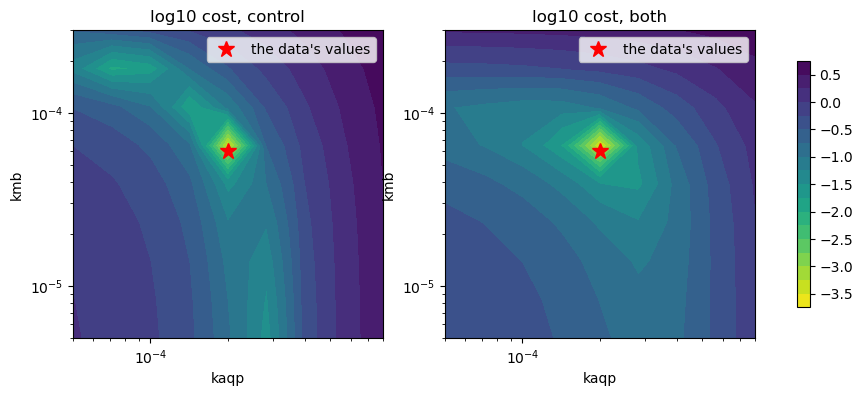

In [9]:
import matplotlib.pyplot as plt

kaqp = np.geomspace(5e-5, 8e-4, 9)
kmb = np.geomspace(5e-6, 3e-4, 9)
maps = {}
for name, rows in (("control", observed["experiment"] == "control"), ("both", slice(None))):
    sub = objective(run, ["kaqp", "kmb"], observed[rows])
    maps[name] = np.array([[0.5 * float(np.sum(sub([a, b]) ** 2)) for a in kaqp] for b in kmb])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, values) in zip(axes, maps.items()):
    shown = ax.contourf(kaqp, kmb, np.log10(values + 1e-12), levels=20, cmap="viridis_r")
    ax.plot(2e-4, 6e-5, "r*", markersize=12, label="the data's values")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("kaqp"); ax.set_ylabel("kmb")
    ax.set_title(f"log10 cost, {name}"); ax.legend()
fig.colorbar(shown, ax=axes, shrink=0.8);

With the control alone, the cost has a **valley**: every (kaqp, kmb) on it matches Krs. With the inhibited
experiment, the valley closes to a minimum near the data's values. Then `least_squares` within the declared bounds
(what `simulation.fit_root_system` does):

In [10]:
from scipy.optimize import least_squares

fit = least_squares(cost, x0=[1., 1.], bounds=cost.bounds, x_scale="jac", xtol=1e-6, ftol=1e-6, gtol=1e-6)
print({name: f"{value:.3e}" for name, value in cost.values(fit.x).items()}, f"after {len(cost.history)} runs")

{'kaqp': '2.011e-04', 'kmb': '6.226e-05'} after 18 runs


## 6. Going further

- **Another protocol.** Krs takes a uniform soil. With a soil that varies (a drier topsoil), MARSHAL's Kcomp
  compensates; the same operator, with other sources, computes it.
- **Another upscaled variable.** Any coarse variable that is the equivalent of finer ones declares
  `upscaling(of=, law=, protocol=)`: the observations then know which model variable they measure.
- **Sensitivity analysis.** `metafspm.scene.scenarios.from_samples` turns a SALib sample into scenarios within the
  declared bounds, `design_table` lays them out to join with the outputs.